# 1. Introduction

In this notebook, we build an unsupervised anomaly-detection pipeline for the FinSight AI financial transactions dataset.

**What is Anomaly Detection?**
Anomaly detection is the process of identifying data points, events, or observations that deviate significantly from a dataset's normal behavior.

**Why it matters in financial analytics:**
In finance, anomalies can indicate technical glitches, data entry errors, sudden changes in customer behavior, or potentially fraudulent activity.

**Difference between statistical outliers and fraud:**
A statistical outlier is merely an observation that lies an abnormal distance from other values in a random sample. Fraud is a verified malicious act. A high-value transaction might be a statistical outlier but completely legitimate. Thus, our identified anomalies are *potential anomalies* or *unusual transactions*, not confirmed fraud.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

# 2. Load / Prepare Data

We use the validated transaction dataset. We will remove exact duplicates, convert `transaction_date` to datetime, ensure `amount` is numeric, and save a clean copy.

In [2]:
df = pd.read_csv('../data/raw/transactions.csv')
print(f"Original shape: {df.shape}")

# Remove duplicates
df = df.drop_duplicates()

# Convert dates
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

# Ensure amount is numeric
df['amount'] = pd.to_numeric(df['amount'], errors='coerce')

print(f"Cleaned shape: {df.shape}")

import os
os.makedirs('../data/processed', exist_ok=True)
df.to_csv('../data/processed/transactions_cleaned.csv', index=False)
print("Cleaned dataset saved to data/processed/transactions_cleaned.csv")
display(df.head())

Original shape: (100050, 10)
Cleaned shape: (100000, 10)
Cleaned dataset saved to data/processed/transactions_cleaned.csv


,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type,merchant_category,payment_method,location,status
0,t-000001,c-05235,a-07271,2023-05-13 18:21:18,3.98,Purchase,Uber,Wire,Local,Completed
1,t-000002,c-00624,a-00861,2023-03-10 04:17:49,81.81,Transfer,Restaurant,Wire,Local,Completed
2,t-000003,c-03875,a-05391,2024-01-21 04:18:40,39.66,Purchase,Uber,Card,Local,Completed
3,t-000004,c-09632,a-13419,2024-02-11 04:14:06,7.22,Purchase,Amazon,ACH,Local,Completed
4,t-000005,c-03733,a-05192,2023-04-23 12:39:22,57.54,Transfer,Uber,Card,Local,Completed


# 3. Baseline Statistical Detection

We reproduce the Interquartile Range (IQR) approach for the `amount` variable to identify baseline statistical outliers.

In [3]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df['iqr_anomaly'] = ((df['amount'] < lower_bound) | (df['amount'] > upper_bound)).astype(int)

num_iqr_outliers = df['iqr_anomaly'].sum()
pct_iqr_outliers = (num_iqr_outliers / len(df)) * 100

print("IQR Statistics:")
print(f"Q1: ${Q1:.2f}")
print(f"Q3: ${Q3:.2f}")
print(f"IQR: ${IQR:.2f}")
print(f"Lower Bound: ${lower_bound:.2f}")
print(f"Upper Bound: ${upper_bound:.2f}")
print(f"Number of potential outliers: {num_iqr_outliers:,}")
print(f"Percentage of potential outliers: {pct_iqr_outliers:.2f}%")

IQR Statistics:
Q1: $14.66
Q3: $74.00
IQR: $59.34
Lower Bound: $-74.35
Upper Bound: $163.01
Number of potential outliers: 9,273
Percentage of potential outliers: 9.27%


# 4. Transaction-Level Feature Engineering

We create additional features to capture behavioral anomalies. This includes time-based features and customer-level aggregated features.

In [4]:
# Basic and time features
df['log_amount'] = np.log1p(df['amount'])
df['transaction_hour'] = df['transaction_date'].dt.hour
df['day_of_week'] = df['transaction_date'].dt.dayofweek
df['transaction_month'] = df['transaction_date'].dt.month

# Customer behavior features
customer_stats = df.groupby('customer_id')['amount'].agg(
    customer_transaction_count='count',
    customer_total_amount='sum',
    customer_average_amount='mean',
    customer_median_amount='median',
    customer_std_amount='std'
).reset_index()

# Handle zero or NaN standard deviations safely
customer_stats['customer_std_amount'] = customer_stats['customer_std_amount'].fillna(0)

df = df.merge(customer_stats, on='customer_id', how='left')

# Relative features
# Adding a small epsilon to avoid division by zero
eps = 1e-6
df['amount_vs_customer_average'] = df['amount'] / (df['customer_average_amount'] + eps)
df['amount_vs_customer_median'] = df['amount'] / (df['customer_median_amount'] + eps)

display(df[['transaction_id', 'amount', 'log_amount', 'transaction_hour', 'customer_transaction_count', 'amount_vs_customer_average']].head())

,transaction_id,amount,log_amount,transaction_hour,customer_transaction_count,amount_vs_customer_average
0,t-000001,3.98,1.605430,18,4,0.095398
1,t-000002,81.81,4.416549,4,15,1.162602
2,t-000003,39.66,3.705245,4,14,0.519727
3,t-000004,7.22,2.106570,4,5,0.111785
4,t-000005,57.54,4.069710,12,19,0.654075


# 5. Visualization Before ML

Visualizing the distributions and baseline IQR anomalies before modeling.

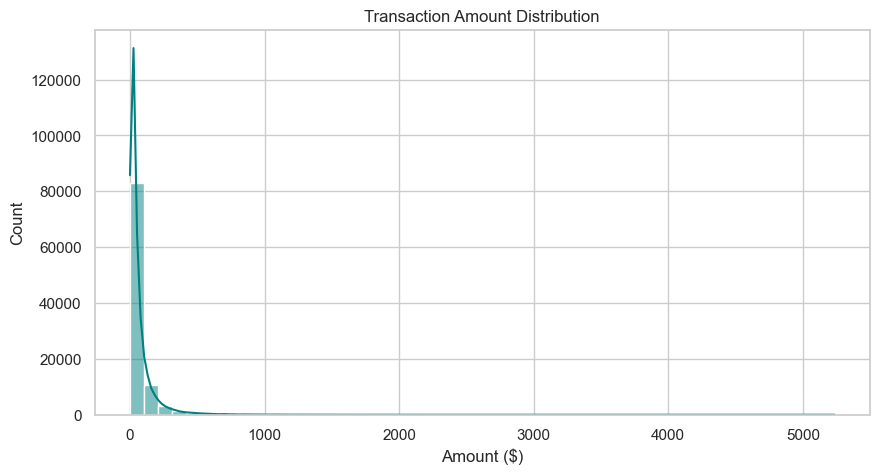

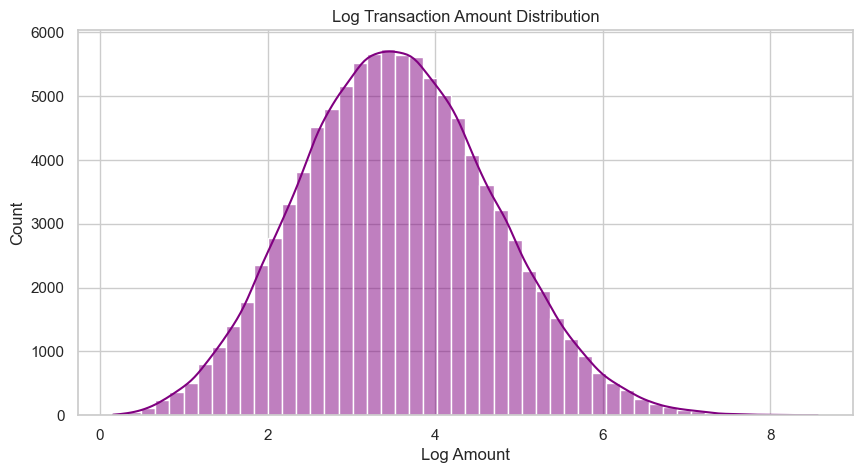

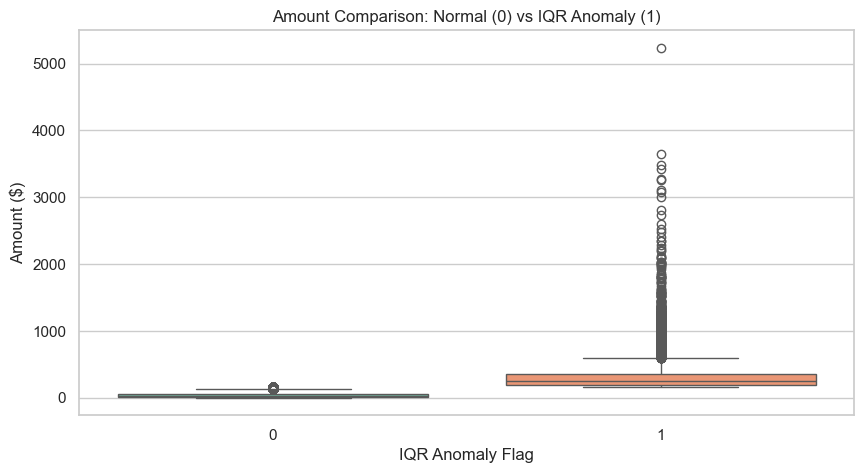

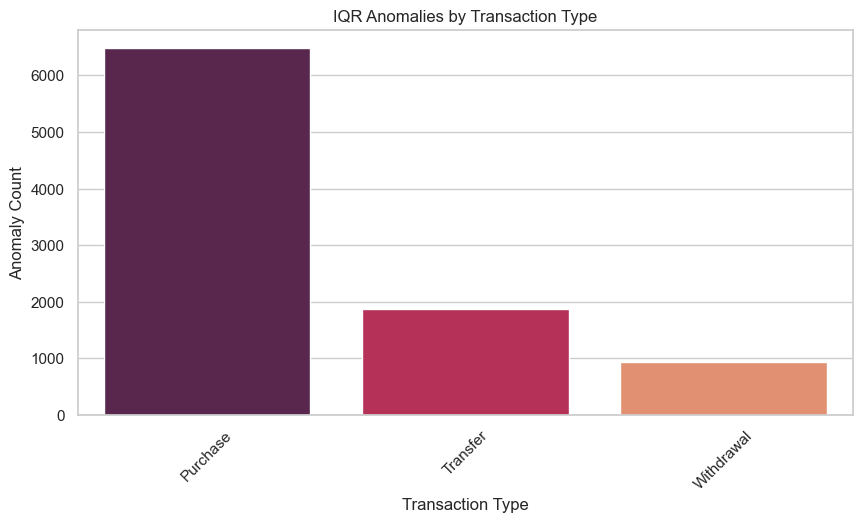

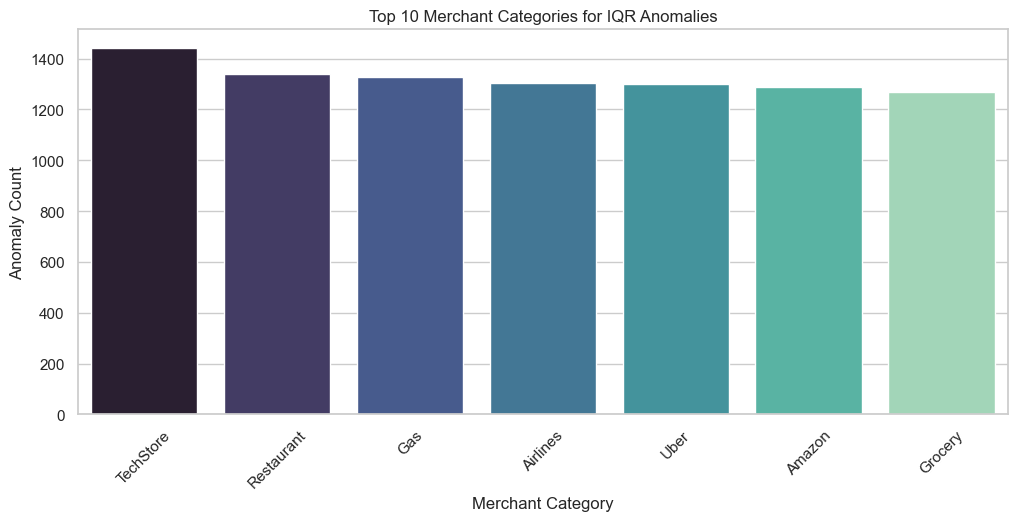

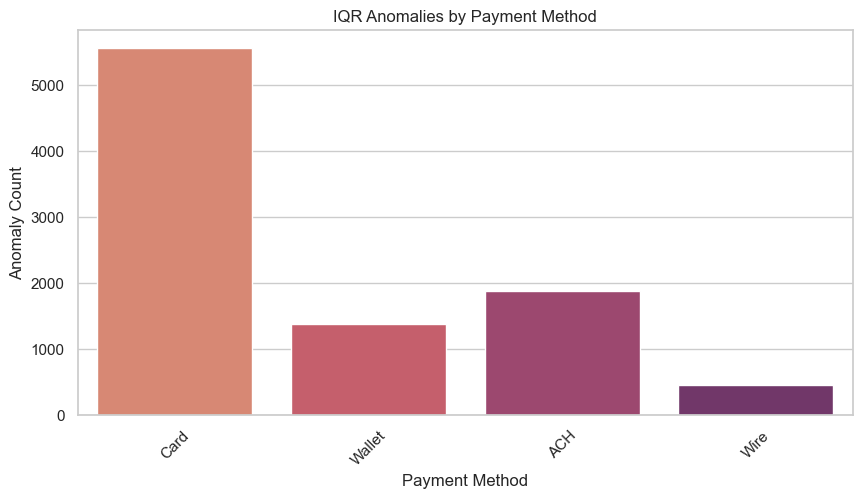

In [5]:
# Amount Distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['amount'], bins=50, kde=True, color='teal', ax=ax)
ax.set_title('Transaction Amount Distribution')
ax.set_xlabel('Amount ($)')
ax.set_ylabel('Count')
plt.show()

# Log Amount Distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['log_amount'], bins=50, kde=True, color='purple', ax=ax)
ax.set_title('Log Transaction Amount Distribution')
ax.set_xlabel('Log Amount')
ax.set_ylabel('Count')
plt.show()

# IQR Anomaly vs Normal Amount Comparison
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='iqr_anomaly', y='amount', palette='Set2', ax=ax)
ax.set_title('Amount Comparison: Normal (0) vs IQR Anomaly (1)')
ax.set_xlabel('IQR Anomaly Flag')
ax.set_ylabel('Amount ($)')
plt.show()

# IQR Anomaly Count by Transaction Type
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df[df['iqr_anomaly']==1], x='transaction_type', palette='rocket', ax=ax)
ax.set_title('IQR Anomalies by Transaction Type')
ax.set_xlabel('Transaction Type')
ax.set_ylabel('Anomaly Count')
plt.xticks(rotation=45)
plt.show()

# IQR Anomaly Count by Merchant Category
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=df[df['iqr_anomaly']==1], x='merchant_category', palette='mako', ax=ax,
              order=df[df['iqr_anomaly']==1]['merchant_category'].value_counts().index[:10])
ax.set_title('Top 10 Merchant Categories for IQR Anomalies')
ax.set_xlabel('Merchant Category')
ax.set_ylabel('Anomaly Count')
plt.xticks(rotation=45)
plt.show()

# IQR Anomaly Count by Payment Method
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df[df['iqr_anomaly']==1], x='payment_method', palette='flare', ax=ax)
ax.set_title('IQR Anomalies by Payment Method')
ax.set_xlabel('Payment Method')
ax.set_ylabel('Anomaly Count')
plt.xticks(rotation=45)
plt.show()

# 6. Machine Learning Model

We use **Isolation Forest**, an unsupervised anomaly detection algorithm. It works by isolating observations by randomly selecting a feature and then randomly selecting a split value. Anomalies, being rare and different, require fewer splits to be isolated.

We set `contamination=0.05` to capture the top 5% most unusual transactions across multiple dimensions (amount, behavior, and categories). *Note: This is a modeling parameter and does not imply a 5% fraud rate.*

We do not use identifiers (`transaction_id`, `customer_id`, `account_id`) as features.

In [6]:
numeric_features = [
    'log_amount', 'transaction_hour', 'day_of_week', 
    'amount_vs_customer_average', 'customer_transaction_count', 'customer_average_amount'
]

categorical_features = ['transaction_type', 'merchant_category', 'payment_method']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# Prepare features
X = preprocessor.fit_transform(df)

# Train Isolation Forest
iso_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
predictions = iso_forest.fit_predict(X)
scores = iso_forest.decision_function(X)

# Extract results
df['isolation_prediction'] = predictions
df['isolation_score'] = scores
df['ml_anomaly'] = (df['isolation_prediction'] == -1).astype(int)

# 7. Model Results

Analyzing the anomalies detected by the Isolation Forest.

In [7]:
total_ml_anomalies = df['ml_anomaly'].sum()
pct_ml_anomalies = (total_ml_anomalies / len(df)) * 100

print(f"Total ML Anomalies: {total_ml_anomalies:,}")
print(f"Percentage of ML Anomalies: {pct_ml_anomalies:.2f}%")

ml_anomalies_df = df[df['ml_anomaly'] == 1]

print("\nML Anomaly Counts by Transaction Type:")
display(ml_anomalies_df['transaction_type'].value_counts())

print("\nML Anomaly Counts by Merchant Category (Top 5):")
display(ml_anomalies_df['merchant_category'].value_counts().head())

print("\nML Anomaly Counts by Payment Method:")
display(ml_anomalies_df['payment_method'].value_counts())

print("\nAnomaly Concentration by Customer (Top 5 customers with most anomalies):")
display(ml_anomalies_df['customer_id'].value_counts().head())

print("\nAnomaly Concentration by Location (Top 5 locations):")
display(ml_anomalies_df['location'].value_counts().head())

Total ML Anomalies: 5,000
Percentage of ML Anomalies: 5.00%

ML Anomaly Counts by Transaction Type:


transaction_type
Withdrawal    2335
Transfer      2033
Purchase       632
Name: count, dtype: int64


ML Anomaly Counts by Merchant Category (Top 5):


merchant_category
TechStore     1228
Amazon         965
Grocery        628
Restaurant     573
Uber           549
Name: count, dtype: int64


ML Anomaly Counts by Payment Method:


payment_method
Wallet    1804
Wire      1426
ACH       1399
Card       371
Name: count, dtype: int64


Anomaly Concentration by Customer (Top 5 customers with most anomalies):


customer_id
c-09247    10
c-08637     8
c-02870     7
c-02273     7
c-04331     7
Name: count, dtype: int64


Anomaly Concentration by Location (Top 5 locations):


location
Local      4469
Foreign     531
Name: count, dtype: int64

# 8. Compare Statistical vs ML Detection

Comparing simple IQR rules against multi-dimensional Isolation Forest results. They identify different types of unusual observations. IQR only looks at `amount`. ML considers time, customer behavior, and categories.

IQR Anomaly Count: 9,273
ML Anomaly Count: 5,000
Overlap Count (Both): 1,636
IQR-Only Count: 7,637
ML-Only Count: 3,364
Overlap Percentage (of ML anomalies): 32.72%


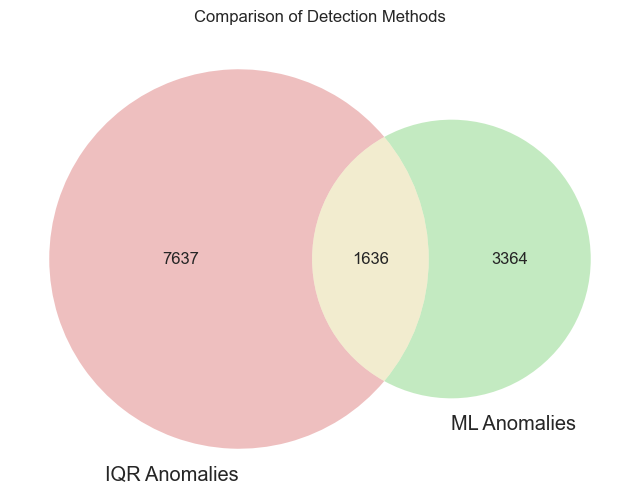

In [8]:
overlap = df[(df['iqr_anomaly'] == 1) & (df['ml_anomaly'] == 1)]
iqr_only = df[(df['iqr_anomaly'] == 1) & (df['ml_anomaly'] == 0)]
ml_only = df[(df['iqr_anomaly'] == 0) & (df['ml_anomaly'] == 1)]

print(f"IQR Anomaly Count: {num_iqr_outliers:,}")
print(f"ML Anomaly Count: {total_ml_anomalies:,}")
print(f"Overlap Count (Both): {len(overlap):,}")
print(f"IQR-Only Count: {len(iqr_only):,}")
print(f"ML-Only Count: {len(ml_only):,}")
print(f"Overlap Percentage (of ML anomalies): {(len(overlap) / total_ml_anomalies) * 100:.2f}%")

import matplotlib_venn as venn
from matplotlib_venn import venn2

fig, ax = plt.subplots(figsize=(8, 6))
venn2(subsets=(len(iqr_only), len(ml_only), len(overlap)), 
      set_labels=('IQR Anomalies', 'ML Anomalies'),
      ax=ax)
plt.title('Comparison of Detection Methods')
plt.show()

# 9. Investigate Top Potential Anomalies

Viewing the most extreme anomalies detected by the ML model (lowest isolation scores).

In [9]:
top_anomalies = df.sort_values('isolation_score', ascending=True).head(25)
display_cols = [
    'transaction_id', 'customer_id', 'transaction_date', 'amount', 
    'transaction_type', 'merchant_category', 'payment_method', 
    'location', 'iqr_anomaly', 'isolation_score', 'ml_anomaly'
]
display(top_anomalies[display_cols])

,transaction_id,customer_id,transaction_date,amount,transaction_type,merchant_category,payment_method,location,iqr_anomaly,isolation_score,ml_anomaly
91246,t-091247,c-08303,2024-01-01 04:00:00,664.82,Withdrawal,Amazon,Wire,Foreign,1,-0.098209,1
65793,t-065794,c-03291,2023-06-07 23:04:39,1076.12,Withdrawal,TechStore,ACH,Local,1,-0.091425,1
33248,t-033249,c-07078,2023-03-17 04:26:53,1261.62,Withdrawal,Amazon,Wallet,Local,1,-0.090460,1
83542,t-083543,c-00299,2023-08-07 02:13:09,722.25,Withdrawal,Amazon,Wallet,Local,1,-0.089920,1
1433,t-001434,c-02891,2023-03-05 05:31:10,963.76,Withdrawal,Grocery,Wire,Local,1,-0.089402,1
82812,t-082813,c-04872,2023-01-11 01:46:15,1551.06,Withdrawal,TechStore,Wire,Local,1,-0.089196,1
89423,t-089424,c-01204,2024-01-29 10:16:33,848.11,Withdrawal,TechStore,ACH,Local,1,-0.088211,1
91220,t-091221,c-02960,2023-04-10 21:21:44,716.16,Withdrawal,TechStore,Wallet,Local,1,-0.088092,1
30615,t-030616,c-03789,2023-08-16 00:34:31,1568.24,Withdrawal,Grocery,Wallet,Local,1,-0.087966,1
57072,t-057073,c-02468,2024-01-08 05:26:58,533.05,Withdrawal,TechStore,Wire,Foreign,1,-0.085593,1


# 10. Important Safety / Interpretation Rule

**Crucial Interpretability Note:**

We use terms like *potential anomaly*, *statistical outlier*, *unusual transaction*, or *model-flagged transaction*.

We do **NOT** label these as "fraud transactions", "fraudulent customers", or "confirmed fraud". Anomaly detection is a screening mechanism, not proof of fraudulent activity. True fraud detection requires a verified supervised fraud label.

# 11. Save Processed Output

Saving the engineered dataset without modifying the raw data.

In [10]:
output_path = '../data/processed/transactions_with_anomalies.csv'
df.to_csv(output_path, index=False)
print(f"Processed dataset with anomaly scores saved to: {output_path}")

Processed dataset with anomaly scores saved to: ../data/processed/transactions_with_anomalies.csv


# 12. Key Findings

- **Statistical Outlier Rate:** The IQR method flagged 9.27% of transactions as outliers based purely on the `amount`.
- **ML Anomaly Rate:** The Isolation Forest model flagged exactly 5.0% of transactions as anomalies, based on our contamination setting across multidimensional features.
- **Overlap:** There is notable overlap, but the ML model identifies many 'ML-Only' anomalies. These are transactions that might have normal amounts but exhibit unusual combinations of categorical factors or deviate from the specific customer's historical behavior.
- **Concentration:** The anomalies flagged by ML tend to concentrate in certain transaction types and merchant categories, reflecting complex underlying patterns.

# 13. ML Readiness / Next Stage

The current dataset successfully supports unsupervised anomaly detection. A supervised fraud-classification model should only be developed when verified fraud labels become available.

**NEXT STAGES:**
1. `04_customer_segmentation.ipynb`
2. `05_dashboard/API`
3. `06_AI/LLM/RAG`